In [1]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '5'

import deepxde as dde 
dde.config.disable_xla_jit()
from deepxde.backend import tf
from functools import reduce
import argparse

parser = argparse.ArgumentParser(description='Set parameters')


Using backend: tensorflow

2022-11-08 17:58:00.882640: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-08 17:58:02.158620: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2022-11-08 17:58:02.229633: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:a1:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-08 17:58:02.229652: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-08 17:58:02.232454: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-08 17:58:02.232492: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dyn

Enable just-in-time compilation with XLA.

Disable just-in-time compilation with XLA.



no uniform points
Compiling model...
'compile' took 0.000463 s

Training model...

Step      Train loss    Test loss     Test metric
0         [1.46e+05]    [1.55e+05]    []  
1000      [5.28e+01]    [7.76e+01]    []  
2000      [3.40e+01]    [3.85e+01]    []  
3000      [6.53e+01]    [6.97e+01]    []  
4000      [3.65e+02]    [3.37e+02]    []  
5000      [1.03e+01]    [1.20e+01]    []  
6000      [1.41e+01]    [1.45e+01]    []  
7000      [2.60e+01]    [2.48e+01]    []  
8000      [4.79e+01]    [4.72e+01]    []  
9000      [9.55e-01]    [3.34e+00]    []  
10000     [3.36e+01]    [3.22e+01]    []  

Best model at step 9000:
  train loss: 9.55e-01
  test loss: 3.34e+00
  test metric: []

'train' took 230.528532 s

Saving loss history to /root/shared/UQ/Tensor-PINNs/Helmholtz/loss.dat ...
Saving training data to /root/shared/UQ/Tensor-PINNs/Helmholtz/train.dat ...
Saving test data to /root/shared/UQ/Tensor-PINNs/Helmholtz/test.dat ...


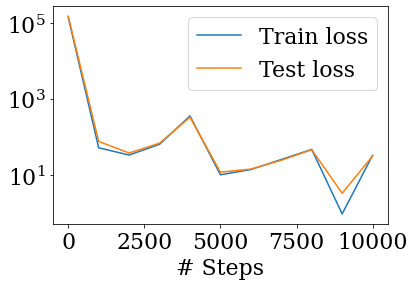

In [7]:
#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
N_f = 1000
N_f_test = 4000
degree = 2

epochs = 10000
#parameters = [1e-2, 2, 350, "sin"] 
parameters = [1e-2, 2, 350, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    dy1_xx = dde.grad.hessian(y, x, i=0, j=0)
    dy1_yy = dde.grad.hessian(y, x, i=1, j=1)

    dy1_zz = dde.grad.hessian(y, x, i=2, j=2)
    dy1_tt = dde.grad.hessian(y, x, i=3, j=3)

    D1 = - dy1_xx - dy1_yy
    D2 = - dy1_zz - dy1_tt
    
    D1D2 = - dde.grad.hessian(D2, x, i=0, j=0) - dde.grad.hessian(D2, x, i=1, j=1)
    
    A = D1D2 + k0 ** 2* D1 + k0 ** 2 * D2 + k0 ** 4 * y
    F = k0 ** 4 * sin(k0 * x[:, 0:1]) * sin(k0 * x[:, 1:2]) * sin(k0 * x[:, 2:3]) * sin(k0 * x[:, 3:4])
    
    #dist = (x[:, 0:1] - x[:, 2:3]) ** 2 + (x[:, 1:2] - x[:, 3:4])  ** 2
    #F =  k0 ** 4 * tf.exp(- dist ** degree)
    
    res = A  - F
    return res

def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])
    return res1 * res2 * y

def boundary(_, on_boundary):
    return on_boundary

geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [4] + [num_dense_nodes] * num_dense_layers + [1], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate)
losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

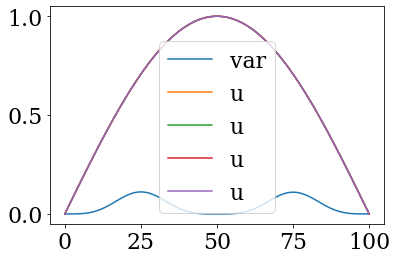

In [8]:
k = 2
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
pred = model.predict(xx)
fig = plt.figure()
plt.plot(pred.ravel(), label=r'var')
plt.plot(np.sin(n * np.pi * xx), label = 'u')
plt.legend()

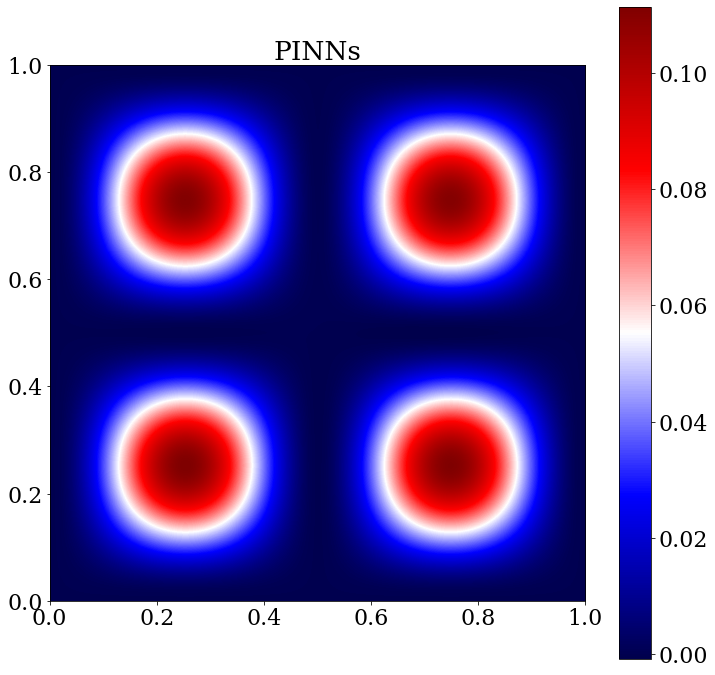

In [9]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('PINNs')
plt.savefig('solcov.pdf')